<div align="center">

<h1>Buzz in Social Media</h1>

<h3>Analyse du dataset UCI <em>Buzz in Social Media</em></h3>

<p><b>Côme Rossary</b> &nbsp;&middot;&nbsp; <b>Batiste Fancellu</b></p>

<p>4 novembre 2026</p>

</div>

---

## Objectif

L'objectif de ce devoir et de ce notebook est d'extraire le maximum d'information pertinente du dataset « Buzz in Social Media », créé par François Kawala, Ahlame Douzal, Eric Gaussier et Eustache Diemert (Université Joseph Fourier / BestofMedia Group) et mis en ligne sur le dépôt UCI en mai 2013.

Ce dataset suit l'activité autour de sujets sur deux réseaux sociaux différents :
- Twitter ;
- Tom's Hardware, un forum consacré aux nouvelles technologies et ayant des dynamiques plus conservatrices.

Avant d'aller plus loin, importons ce dataset.

In [3]:
import os

# Sur Google Colab : téléchargement du dossier du projet depuis Google Drive.
# En local : on suppose être déjà dans le dossier du projet.
if os.path.exists("/content"):
    if not os.path.exists("/content/projet"):
        !pip install -q gdown
        !gdown -q --folder 1oaoxufMxfSdoyX4hrLdCGesuG3NUDZ57 -O /content/projet
    %cd /content/projet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

## Présentation des données

Le dataset contient un dossier par réseau social, `Twitter` et `TomsHardware`, avec deux fichiers chacun :

- `*.data` : les données, au format CSV sans en-tête, une ligne par sujet ;
- `*.names` : la documentation du fichier `.data`, au format texte habituel des datasets UCI.

### Ce que nous apprend le fichier `.names`

Pour les deux datasets, chaque ligne correspond à un sujet (un exemple). Les attributs sont des indicateurs d'activité mesurés à plusieurs pas de temps consécutifs. La dernière colonne est la valeur à prédire.

**Dossier `Twitter`** : chaque ligne est composée de 77 attributs, soit 11 indicateurs × 7 pas de temps (t = 0 à 6), dans cet ordre :

| Colonnes | Indicateur | Signification |
|---|---|---|
| 0 à 6 | NCD, *Number of Created Discussions* | nombre de discussions créées sur le sujet |
| 7 à 13 | AI, *Author Increase* | nombre de nouveaux auteurs sur le sujet |
| 14 à 20 | AS(NA), *Attention Level (authors)* | part des auteurs du réseau qui écrivent sur le sujet |
| 21 à 27 | BL, *Burstiness Level* | NCD / NAD : part des discussions actives qui viennent d'être créées |
| 28 à 34 | NAC, *Number of Atomic Containers* | nombre de contributions (tweets) sur le sujet |
| 35 à 41 | AS(NAC), *Attention Level (contributions)* | part des contributions du réseau qui concernent le sujet |
| 42 à 48 | CS, *Contribution Sparseness* | dispersion des contributions entre les discussions du sujet |
| 49 à 55 | AT, *Author Interaction* | nombre moyen d'auteurs par discussion |
| 56 à 62 | NA, *Number of Authors* | nombre d'auteurs actifs sur le sujet |
| 63 à 69 | ADL, *Average Discussion Length* | longueur moyenne d'une discussion |
| 70 à 76 | NAD, *Number of Active Discussions* | nombre de discussions actives sur le sujet |
| 77 | cible | nombre moyen de discussions actives (NAD) dans les semaines suivantes |

**Dossier `TomsHardware`** : chaque ligne est composée de 96 attributs, soit 12 indicateurs × 8 pas de temps (t = 0 à 7). Ce sont les mêmes indicateurs dans un ordre différent, plus un indicateur propre au forum :

| Colonnes | Indicateur |
|---|---|
| 0 à 7 | NCD |
| 8 à 15 | BL |
| 16 à 23 | NAD |
| 24 à 31 | AI |
| 32 à 39 | NAC, ici le nombre de messages postés |
| 40 à 47 | ND, *Number of Displays* : nombre d'affichages des discussions du sujet |
| 48 à 55 | CS |
| 56 à 63 | AT |
| 64 à 71 | NA |
| 72 à 79 | ADL |
| 80 à 87 | AS(NA) |
| 88 à 95 | AS(NAC) |
| 96 | cible : nombre moyen d'affichages (ND) dans les semaines suivantes |

## État des données

Avant toute analyse, vérifions que les deux fichiers sont propres :

1. le nombre de colonnes est celui annoncé par le `.names` : 77 + 1 pour Twitter, 96 + 1 pour Tom's Hardware ;
2. toutes les colonnes sont numériques ;
3. aucune valeur manquante ni infinie ;
4. aucune valeur négative : ce sont des comptes, des ratios et des moyennes ;
5. les indicateurs de comptage (NCD, AI, NAC, NA, NAD, ND) ne contiennent que des entiers ;
6. les indicateurs définis sur [0, 1] (AS(NA), AS(NAC), BL, CS) restent dans cet intervalle ;
7. aucune colonne constante, qui n'apporterait aucune information ;
8. nombre de lignes dupliquées et de lignes entièrement nulles, à connaître avant de modéliser.

In [4]:
from pathlib import Path

# Indicateurs dans l'ordre des colonnes de chaque fichier .data, et nombre de pas de temps (cf. .names).
DATASETS = {
    "Twitter": {
        "n_steps": 7,
        "indicateurs": ["NCD", "AI", "AS(NA)", "BL", "NAC", "AS(NAC)", "CS", "AT", "NA", "ADL", "NAD"],
    },
    "TomsHardware": {
        "n_steps": 8,
        "indicateurs": ["NCD", "BL", "NAD", "AI", "NAC", "ND", "CS", "AT", "NA", "ADL", "AS(NA)", "AS(NAC)"],
    },
}
COMPTAGES = {"NCD", "AI", "NAC", "NA", "NAD", "ND"}   # valeurs entières attendues
RATIOS = {"AS(NA)", "AS(NAC)", "BL", "CS"}            # valeurs dans [0, 1] attendues


def charger(nom):
    """Charge <nom>.data (cherché depuis le dossier courant) et nomme les colonnes X_t ; la dernière est 'cible'."""
    fichiers = list(Path(".").rglob(f"{nom}.data"))
    assert fichiers, f"{nom}.data introuvable depuis {Path.cwd()}"
    spec = DATASETS[nom]
    colonnes = [f"{ind}_{t}" for ind in spec["indicateurs"] for t in range(spec["n_steps"])] + ["cible"]
    df = pd.read_csv(fichiers[0], header=None)
    df.columns = colonnes[: df.shape[1]] if df.shape[1] <= len(colonnes) else range(df.shape[1])
    return df


def verifier(nom, df):
    spec = DATASETS[nom]
    num = df.select_dtypes("number")
    comptages = [c for c in num.columns if str(c).split("_")[0] in COMPTAGES]
    ratios = [c for c in num.columns if str(c).split("_")[0] in RATIOS]
    return {
        "lignes": len(df),
        "colonnes": df.shape[1],
        "colonnes attendues": len(spec["indicateurs"]) * spec["n_steps"] + 1,
        "colonnes non numériques": df.shape[1] - num.shape[1],
        "valeurs manquantes": int(df.isna().sum().sum()),
        "valeurs infinies": int(np.isinf(num).sum().sum()),
        "valeurs négatives": int((num < 0).sum().sum()),
        "comptages non entiers": int((df[comptages] % 1 != 0).sum().sum()),
        "ratios hors [0, 1]": int(((df[ratios] < 0) | (df[ratios] > 1)).sum().sum()),
        "colonnes constantes": int((df.nunique() <= 1).sum()),
        "lignes dupliquées": int(df.duplicated().sum()),
        "lignes entièrement nulles": int((num.drop(columns="cible", errors="ignore") == 0).all(axis=1).sum()),
    }


data = {nom: charger(nom) for nom in DATASETS}
pd.DataFrame({nom: verifier(nom, df) for nom, df in data.items()})

,Twitter,TomsHardware
lignes,583250,28179
colonnes,78,97
colonnes attendues,78,97
colonnes non numériques,0,0
valeurs manquantes,0,0
valeurs infinies,0,0
valeurs négatives,0,0
comptages non entiers,0,0
"ratios hors [0, 1]",0,0
colonnes constantes,0,0


Tout est conforme. On remarque seulement un nombre notable de lignes dupliquées : 6 016 sur Twitter, soit 1,0 % du dataset, et 25 sur Tom's Hardware, soit 0,1 %. Il s'agit probablement de sujets avec très peu d'interactions (un tweet ou une page vue à un ou deux pas de temps), dont le motif d'activité se répète à l'identique d'un sujet à l'autre. Pour l'instant, nous n'en tiendrons pas compte.

## Première approche : la régression

Le premier objectif naturel, et celui pour lequel les auteurs ont construit le dataset, est de prédire le buzz, c'est-à-dire la dernière colonne, à partir des colonnes précédentes, qui décrivent l'activité observée sur la fenêtre. C'est un problème de régression, à traiter séparément pour chaque dataset puisque la cible n'est pas la même : nombre moyen de discussions actives pour Twitter, nombre moyen d'affichages pour Tom's Hardware.

Les auteurs précisent dans le `.names` que leurs résultats sont corrects mais limités par le déséquilibre du dataset (beaucoup de sujets sans buzz, quelques sujets énormes). Ils suggèrent de normaliser les attributs et d'ajouter comme attributs supplémentaires les différences entre pas de temps consécutifs.

### La cible

Les auteurs préviennent que le dataset est déséquilibré (grande majorité de sujets sans buzz). On commence donc par observer ce déséquilibre, pour décider s'il faut changer d'échelle la cible.

In [5]:
pd.DataFrame({
    "médiane": {nom: df["cible"].median() for nom, df in data.items()},
    "max": {nom: df["cible"].max() for nom, df in data.items()},
    "part de sujets avec cible = 0": {nom: df["cible"].eq(0).mean() for nom, df in data.items()},
    "part du buzz total détenue par 1 % des sujets": {
        nom: df["cible"].nlargest(len(df) // 100).sum() / df["cible"].sum() for nom, df in data.items()
    },
}).T.round(3)

,Twitter,TomsHardware
médiane,25.500,359.000
max,75724.500,265916.500
part de sujets avec cible = 0,0.033,0.004
part du buzz total détenue par 1 % des sujets,0.224,0.302


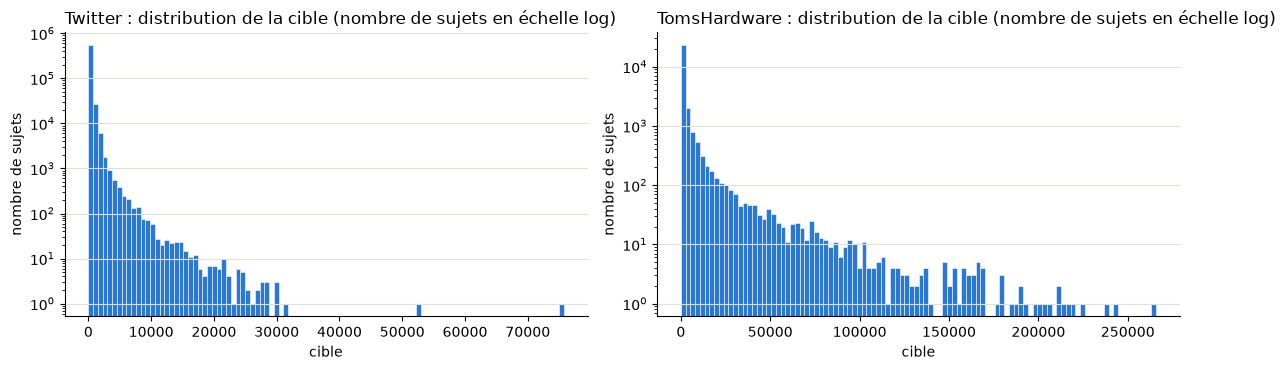

In [6]:
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "axes.titlelocation": "left",
})
BLEU = "#2a78d6"

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nom, df) in zip(axes, data.items()):
    ax.hist(df["cible"], bins=100, color=BLEU, edgecolor="white", linewidth=0.4)
    ax.set_yscale("log")
    ax.set_title(f"{nom} : distribution de la cible (nombre de sujets en échelle log)")
    ax.set_xlabel("cible")
    ax.set_ylabel("nombre de sujets")
fig.tight_layout()
plt.show()

Le déséquilibre est net. Sur Twitter, la moitié des sujets ont une cible inférieure à 26 et le maximum dépasse 75 000 ; sur Tom's Hardware, médiane 359 et maximum 266 000. L'échelle log de l'axe vertical est nécessaire pour voir autre chose qu'une barre à zéro : presque tous les sujets sont dans la première barre, et la queue de distribution s'étire sur cinq ordres de grandeur avec une poignée de sujets.

C'est un problème pour une régression classique. L'erreur quadratique donne à un sujet à 75 000 prédit à 50 000 le même poids que des milliers de petits sujets prédits à 50 au lieu de 25. Le modèle ajusterait donc une poignée de sujets énormes et ignorerait tous les autres, et son score ne refléterait que ces quelques sujets. De plus, une erreur de 25 000 n'a pas le même sens pour un sujet à 100 et pour un sujet à 75 000 : ce qui compte pour un buzz, c'est l'ordre de grandeur.

On propose donc de travailler sur log(1 + cible) plutôt que sur la cible brute, pour trois raisons :

- une erreur sur le log est une erreur relative : se tromper d'un facteur 2 pèse pareil pour un sujet à 10 et pour un sujet à 10 000, ce qui est la bonne notion d'erreur pour un buzz ;
- la transformation compresse la queue de distribution : les sujets énormes ne dominent plus l'ajustement, et la cible devient à peu près en cloche, ce qui convient bien aux modèles linéaires et aux moindres carrés ;
- le « + 1 » permet de garder les sujets à cible nulle, puisque log(0) n'existe pas, et envoie 0 sur 0.

Vérifions l'effet sur les deux datasets.

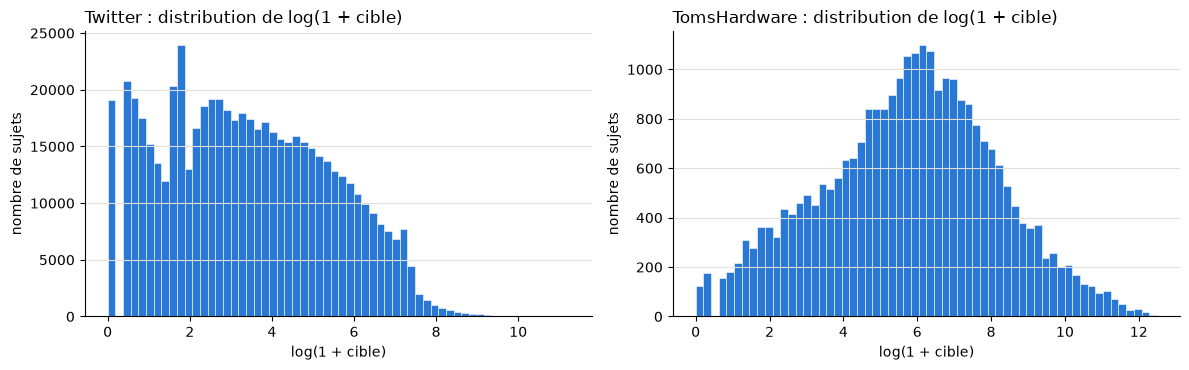

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nom, df) in zip(axes, data.items()):
    ax.hist(np.log1p(df["cible"]), bins=60, color=BLEU, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{nom} : distribution de log(1 + cible)")
    ax.set_xlabel("log(1 + cible)")
    ax.set_ylabel("nombre de sujets")
fig.tight_layout()
plt.show()

Les deux distributions tiennent maintenant sur une échelle de 0 à 12 sans queue extrême, et celle de Tom's Hardware est presque gaussienne. C'est sur cette cible transformée qu'on fera la régression.